# **Tools**

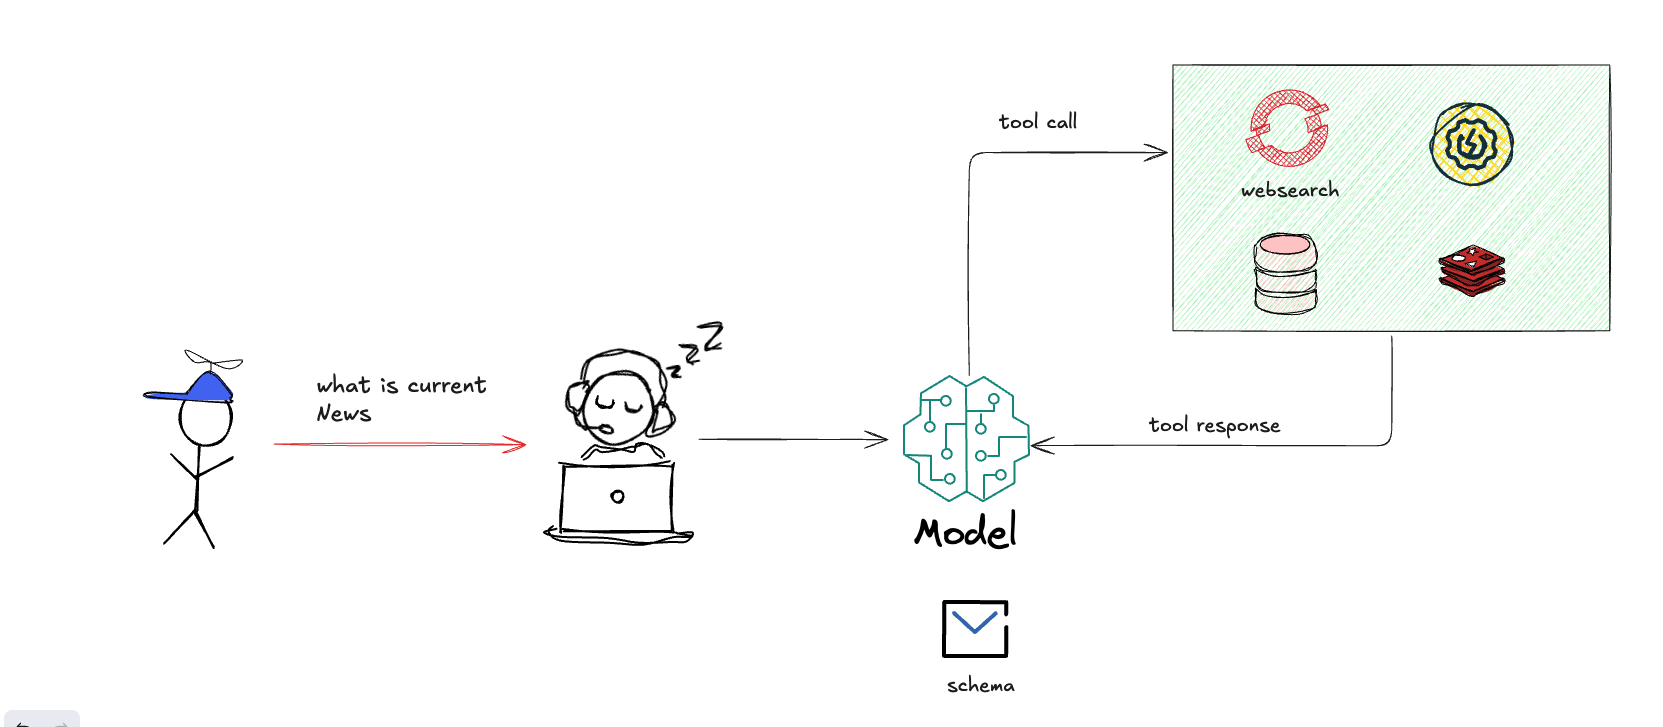

In [15]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [16]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini")

llm.invoke("hi").content



'Hello! How can I assist you today?'

In [17]:
!pip install -U ddgs


[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [18]:
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool

@tool
def search_duckduckgo(query: str) -> str:
    """ 
    This tool search the latest news on DuckDuckGo search for given query and also it will return the result
    """
    duck_search = DuckDuckGoSearchRun()

    return duck_search.invoke(query)


In [19]:
duck_search = DuckDuckGoSearchRun()
duck_search.invoke("test")

'A test is a procedure, method, or examination designed to evaluate, assess, or measure the qualities, performance, knowledge, abilities, reliability, or other attributes of a person, object, system, or concept.'

In [22]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper
from langchain_core.tools import tool

@tool
def arxiv_tool(query: str) -> str:
    """ 
    this tool allows you to query the Arxiv db for research papers
    """
    arxive_query = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())

    return arxive_query.invoke(query)


## **WikiPedia**

In [32]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_core.tools import tool

@tool
def wiki_tool(query: str) -> str:
    """ 
    this tool allows you to query the Arxiv db for research papers
    """
    wiki_runner = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())

    return wiki_runner.invoke(query)

In [31]:
wiki_runner = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
wiki_runner.invoke("virat kholi")

"Page: Virat Kohli\nSummary: Virat Kohli (born 5 November 1988) is an Indian international cricketer and former all-format captain of the Indian national team. He is a right-handed batter and an occasional right-arm medium-pace bowler. Considered one of the greatest batters in cricket, he has been acclaimed for his batting skills and records. Kohli has the most centuries in ODIs and the second-most centuries in international cricket with 86 tons across all formats. He is also the leading run-scorer in the Indian Premier League.\nKohli was the captain of the 2008 U19 World Cup winning team and was a crucial member of the Indian teams that won 2011 Cricket World Cup, 2013 Champions Trophy, 2024 T20 World Cup, and 2025 Champions Trophy. He plays for Royal Challengers Bengaluru in the Indian Premier League and for Delhi in domestic cricket. In 2013, Kohli was ranked number one in the ODI batting rankings. In 2015, he achieved the same in T20I cricket. In 2018, he was ranked number one in T

In [28]:
@tool
def kubernetes_analyser(object: str):
    """ 
    this connects to dev envinroment of eks and that region us-west-1 connect all the and objects and this helps
    to trubleshoot all the kubernetes realted issues and also it give details about your objects
    """

    info = {
        "pod" : "pods are the smallest deployable object",
        "Replicaset" : "this object always maintains the state",
        "service" : "Service object in kubernetes helps to connect all pods namespaces etc",
    }

    return info.get(object,"No information available for this object")




In [29]:
kubernetes_analyser.invoke("pod")

'pods are the smallest deployable object'

In [33]:
tools = [kubernetes_analyser,arxiv_tool,wiki_tool,search_duckduckgo]

In [34]:
llm_with_tools = llm.bind_tools(tools)

In [35]:
llm_with_tools.invoke("What is pod")

AIMessage(content='In Kubernetes, a **pod** is the smallest and simplest unit that represents a set of running containers on the cluster. Here are some key points about pods:\n\n1. **Single or Multiple Containers**: A pod can contain one or more containers that share the same network namespace, meaning they can communicate with each other using `localhost`. This allows you to run tightly coupled applications that need to share resources.\n\n2. **Shared Storage**: Containers in a pod can share storage volumes, allowing them to exchange data easily and collaborate on tasks.\n\n3. **Lifecycle**: Pods have a defined lifecycle. They can be created, running, succeeded, or failed. Kubernetes orchestrates the lifecycle of pods, ensuring they are started, stopped, and maintained according to specifications.\n\n4. **Networking**: Each pod is assigned a unique IP address, and containers within the pod can communicate with each other using this IP address. They can communicate with other pods usin

In [36]:
llm_with_tools.invoke("What current news")

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 187, 'total_tokens': 205, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_758480d42c', 'id': 'chatcmpl-Ejngi5xKFBPKQE4m8QiKwQT9DKWs6', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1d591-d2fe-7aa1-9f8a-51bf538f006c-0', tool_calls=[{'name': 'search_duckduckgo', 'args': {'query': 'current news'}, 'id': 'call_v0FTkHxp3sf8CXPaMZF0vB0A', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 187, 'output_tokens': 18, 'total_tokens': 205, 'input_token_d

In [37]:
llm_with_tools.invoke("What current news").tool_calls

[{'name': 'search_duckduckgo',
  'args': {'query': 'current news'},
  'id': 'call_12YXRiqzFkV7xNyJpHHzCVxJ',
  'type': 'tool_call'}]

In [ ]:
import os
import boto3
AWS_ACCESS_KEY = ""
AWS_SECRET_KEY = ""
AWS_REGION = "ap-northeast-1"

s3_client = boto3.client(
    "s3",
    aws_access_key_id=AWS_ACCESS_KEY,
    aws_secret_access_key=AWS_SECRET_KEY,
    region_name=AWS_REGION,
)

In [42]:
import os
import boto3
import duckdb
from typing import Annotated, TypedDict
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

# Initialize AWS S3 client
s3_client = boto3.client("s3")


# --- 1. Define S3 Analysis Tools ---

@tool
def list_s3_objects(bucket: str, prefix: str = "", max_keys: int = 50) -> str:
    """List files (keys), sizes, and last-modified timestamps in an S3 bucket/prefix."""
    try:
        response = s3_client.list_objects_v2(
            Bucket=bucket, Prefix=prefix, MaxKeys=max_keys
        )
        contents = response.get("Contents", [])
        if not contents:
            return f"No objects found in s3://{bucket}/{prefix}"

        lines = [
            f"- {obj['Key']} | Size: {obj['Size'] / 1024:.2f} KB | Modified: {obj['LastModified']}"
            for obj in contents
        ]
        return "\n".join(lines)
    except Exception as e:
        return f"Error listing S3 objects: {str(e)}"


@tool
def inspect_s3_file_preview(bucket: str, key: str, num_bytes: int = 4096) -> str:
    """Read the first few KB of a text/CSV/JSON/log file from S3 to inspect its schema or structure."""
    try:
        response = s3_client.get_object(
            Bucket=bucket, Key=key, Range=f"bytes=0-{num_bytes - 1}"
        )
        data = response["Body"].read().decode("utf-8", errors="replace")
        return f"Preview of s3://{bucket}/{key} (first {num_bytes} bytes):\n\n{data}"
    except Exception as e:
        return f"Error previewing file: {str(e)}"


@tool
def query_s3_with_sql(sql_query: str) -> str:
    """
    Execute a DuckDB SQL query directly against S3 CSV, Parquet, or JSON files.
    Example query: SELECT category, COUNT(*), AVG(price) FROM 's3://my-bucket/sales.parquet' GROUP BY 1 LIMIT 20;
    Always use LIMIT to keep output concise.
    """
    try:
        con = duckdb.connect(database=":memory:")
        con.execute("INSTALL httpfs; LOAD httpfs;")
        # Pass AWS credentials from environment/boto3 session to DuckDB
        session = boto3.Session()
        creds = session.get_credentials().get_frozen_credentials()
        region = session.region_name or "us-east-1"

        con.execute(f"""
            CREATE SECRET (
                TYPE S3,
                KEY_ID '{creds.access_key}',
                SECRET '{creds.secret_key}',
                REGION '{region}'
                {f", SESSION_TOKEN '{creds.token}'" if creds.token else ""}
            );
        """)
        df = con.execute(sql_query).df()
        if len(df) > 100:
            return f"Showing top 100 of {len(df)} rows:\n" + df.head(100).to_markdown(index=False)
        return df.to_markdown(index=False)
    except Exception as e:
        return f"SQL Execution Error: {str(e)}"


tools = [list_s3_objects, inspect_s3_file_preview, query_s3_with_sql]


# --- 2. Build LangGraph State & Graph ---

class AgentState(TypedDict):
    messages: Annotated[list, add_messages]


llm = ChatOpenAI(model="gpt-4o", temperature=0).bind_tools(tools)

SYSTEM_PROMPT = """You are an AWS S3 Data & Storage Analyst agent.
Follow this workflow:
1. First list objects in the target bucket/prefix to understand what files exist and check their sizes.
2. Preview file headers/schemas before running heavy queries.
3. For CSV, Parquet, or JSON datasets, write targeted DuckDB SQL queries using `s3://bucket/key` paths instead of reading entire files.
4. Always apply `LIMIT` clauses in SQL queries so you never overflow your context window.
5. Summarize key findings, anomalies, and storage insights clearly."""


def agent_node(state: AgentState):
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    response = llm.invoke(messages)
    return {"messages": [response]}


workflow = StateGraph(AgentState)
workflow.add_node("agent", agent_node)
workflow.add_node("tools", ToolNode(tools))

workflow.add_edge(START, "agent")
workflow.add_conditional_edges("agent", tools_condition)
workflow.add_edge("tools", "agent")

s3_agent = workflow.compile()


# --- 3. Run the Agent ---

if __name__ == "__main__":
    user_request = (
        "Analyze the bucket 'skillopstatichosting'  "
        "Tell me what files are there, check the schema, and find the top 5 products by revenue."
    )
    result = s3_agent.invoke({"messages": [HumanMessage(content=user_request)]})
    print(result["messages"][-1].content)

The bucket 'skillopstatichosting' contains the following files:

1. **error.html**
   - Size: 0.97 KB
   - Last Modified: 2026-11-08

2. **index.html**
   - Size: 7.70 KB
   - Last Modified: 2026-11-08

3. **styles.css**
   - Size: 7.04 KB
   - Last Modified: 2026-11-08

These files appear to be related to a static website (HTML and CSS files). There are no data files like CSV, Parquet, or JSON that would typically contain product or revenue information. Therefore, I cannot perform an analysis to find the top 5 products by revenue based on the current contents of this bucket. If there are other buckets or prefixes you would like me to check, please let me know!


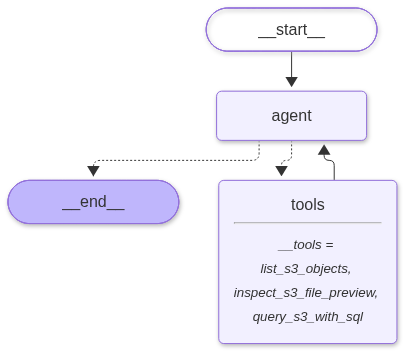

In [43]:
from IPython.display import Image,display

Image(s3_agent.get_graph().draw_mermaid_png())